# OIBSIP Task 3 – Car Price Prediction with Machine Learning

This project predicts used-car selling prices. It supports both common CarDekho columns and alternate schemas such as `brand`, `year`, `distance_driven`, and `selling_price`.

**Dataset note:** `data/sample_car_data.csv` is synthetic demonstration data so the workflow runs immediately. For internship submission, download a real Kaggle dataset such as **Vehicle dataset from cardekho**, place its CSV in `data/`, then rerun all cells. Never submit synthetic-data metrics as real-world results.

## Quick start
From this folder run `python setup.py install`, then `python setup.py check`, then `python setup.py notebook`.

## 1. Imports and configuration

In [31]:
from pathlib import Path
import re, warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
import joblib

RANDOM_STATE = 42
CURRENT_YEAR = pd.Timestamp.today().year
PROJECT_DIR = Path.cwd()
DATA_DIR = PROJECT_DIR / "data"
OUTPUT_DIR = PROJECT_DIR / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid")
print("Project:", PROJECT_DIR)

Project: F:\gitproject\OIBSIP\OIBSIP_DataScience_Task3_CarPricePrediction_Full\OIBSIP\DataScience-Task3-CarPricePrediction


## 2. Load CSV
The notebook automatically prefers a real CSV over the included sample.

In [17]:
csv_files = sorted(DATA_DIR.glob("*.csv"))
real_files = [p for p in csv_files if p.name.lower() != "sample_car_data.csv"]
DATA_PATH = real_files[0] if real_files else DATA_DIR / "sample_car_data.csv"
if not DATA_PATH.exists():
    raise FileNotFoundError(f"No CSV found in {DATA_DIR}")
df_raw = pd.read_csv(DATA_PATH)
print("Using:", DATA_PATH.name, "| Shape:", df_raw.shape)
display(df_raw.head())

Using: sample_car_data.csv | Shape: (180, 7)


,brand,model,year,fuel_type,transmission_type,distance_driven,selling_price
0,Maruti,Maruti Model 1,2020,Petrol,Automatic,18321,2.82
1,Tata,Tata Model 2,2016,Diesel,Automatic,156221,4.12
2,Ford,Ford Model 3,2015,Petrol,Automatic,126142,3.88
3,Toyota,Toyota Model 4,2016,Petrol,Manual,73729,5.62
4,Ford,Ford Model 5,2021,Diesel,Manual,113581,5.55


## 3. Normalize and map column names

In [18]:
def normalize_column(name):
    return re.sub(r"[^a-z0-9]+", "_", str(name).strip().lower()).strip("_")

df = df_raw.copy()
df.columns = [normalize_column(c) for c in df.columns]
aliases = {
    "selling_price": ["selling_price","sellingprice","price"],
    "year": ["year","model_year","manufacturing_year"],
    "distance_driven": ["distance_driven","kms_driven","km_driven","kilometers_driven","mileage_km"],
    "fuel_type": ["fuel_type","fuel"],
    "transmission_type": ["transmission_type","transmission"],
    "brand": ["brand","make","company"],
    "car_name": ["car_name","name","car"],
    "model": ["model","variant"],
    "present_price": ["present_price","presentprice","current_price"],
    "seller_type": ["seller_type"],
    "owner": ["owner","previous_owners"],
    "location": ["location","city"],
    "car_type": ["car_type","body_type"],
    "version": ["version"]
}
rename={}
for canonical, options in aliases.items():
    if canonical not in df.columns:
        for option in options:
            if option in df.columns:
                rename[option]=canonical
                break
df=df.rename(columns=rename)
if "brand" not in df.columns and "car_name" in df.columns:
    df["brand"]=df["car_name"].astype(str).str.strip().str.split().str[0]
if "selling_price" not in df.columns:
    raise ValueError(f"Target selling price column not found. Available: {df.columns.tolist()}")
print(df.columns.tolist())
display(df.head())

['brand', 'model', 'year', 'fuel_type', 'transmission_type', 'distance_driven', 'selling_price']


,brand,model,year,fuel_type,transmission_type,distance_driven,selling_price
0,Maruti,Maruti Model 1,2020,Petrol,Automatic,18321,2.82
1,Tata,Tata Model 2,2016,Diesel,Automatic,156221,4.12
2,Ford,Ford Model 3,2015,Petrol,Automatic,126142,3.88
3,Toyota,Toyota Model 4,2016,Petrol,Manual,73729,5.62
4,Ford,Ford Model 5,2021,Diesel,Manual,113581,5.55


## 4. Clean data
Remove duplicates and invalid targets; standardize categorical text. Predictor nulls are imputed inside the pipeline.

In [19]:
before=len(df)
df=df.drop_duplicates().copy()
print("Duplicates removed:", before-len(df))
for col in ["selling_price","year","distance_driven","present_price","owner"]:
    if col in df.columns:
        df[col]=pd.to_numeric(df[col],errors="coerce")
before=len(df)
df=df.dropna(subset=["selling_price"])
df=df[df["selling_price"]>0].copy()
print("Invalid target rows removed:",before-len(df))
for col in ["brand","car_name","model","fuel_type","transmission_type","seller_type","location","car_type","version"]:
    if col in df.columns:
        df[col]=(df[col].astype("string").str.strip()
                 .str.replace(r"\s+"," ",regex=True).str.title())
        df[col]=df[col].replace({"":pd.NA,"Nan":pd.NA,"None":pd.NA})
if "year" in df.columns:
    df.loc[(df["year"]<1950)|(df["year"]>CURRENT_YEAR),"year"]=np.nan
print("Clean shape:",df.shape)
display(df.head())

Duplicates removed: 0
Invalid target rows removed: 0
Clean shape: (180, 7)


,brand,model,year,fuel_type,transmission_type,distance_driven,selling_price
0,Maruti,Maruti Model 1,2020.0,Petrol,Automatic,18321,2.82
1,Tata,Tata Model 2,2016.0,Diesel,Automatic,156221,4.12
2,Ford,Ford Model 3,2015.0,Petrol,Automatic,126142,3.88
3,Toyota,Toyota Model 4,2016.0,Petrol,Manual,73729,5.62
4,Ford,Ford Model 5,2021.0,Diesel,Manual,113581,5.55


## 5. Feature engineering
Calculate car age from year and extract brand from car name when brand is absent.

In [20]:
if "year" in df.columns:
    df["car_age"]=CURRENT_YEAR-df["year"]
if "brand" not in df.columns and "car_name" in df.columns:
    df["brand"]=df["car_name"].astype("string").str.split().str[0].str.title()
for col in ["unnamed_0","index","car_name"]:
    if col in df.columns: df=df.drop(columns=col)
print("Features:",df.columns.tolist())
display(df.head())

Features: ['brand', 'model', 'year', 'fuel_type', 'transmission_type', 'distance_driven', 'selling_price', 'car_age']


,brand,model,year,fuel_type,transmission_type,distance_driven,selling_price,car_age
0,Maruti,Maruti Model 1,2020.0,Petrol,Automatic,18321,2.82,6.0
1,Tata,Tata Model 2,2016.0,Diesel,Automatic,156221,4.12,10.0
2,Ford,Ford Model 3,2015.0,Petrol,Automatic,126142,3.88,11.0
3,Toyota,Toyota Model 4,2016.0,Petrol,Manual,73729,5.62,10.0
4,Ford,Ford Model 5,2021.0,Diesel,Manual,113581,5.55,5.0


## 6. EDA – selling price distribution

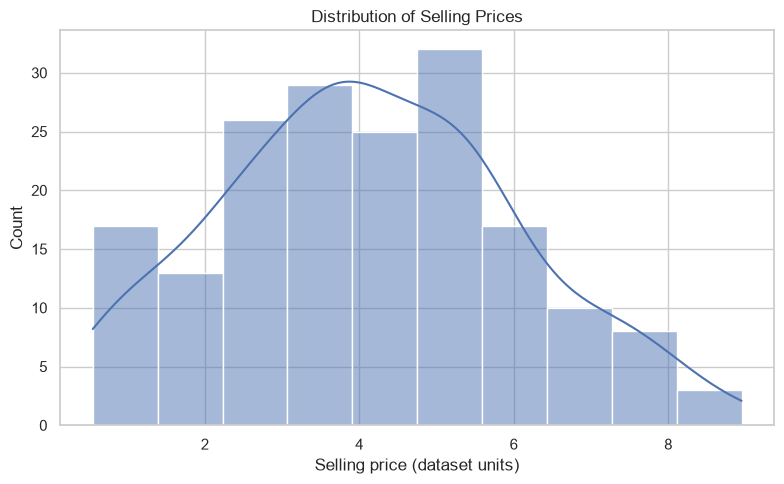

In [21]:
plt.figure(figsize=(8,5))
sns.histplot(df["selling_price"],kde=True)
plt.title("Distribution of Selling Prices")
plt.xlabel("Selling price (dataset units)")
plt.tight_layout()
plt.savefig(OUTPUT_DIR/"selling_price_distribution.png",dpi=150)
plt.show()

## 7. EDA – price by fuel type

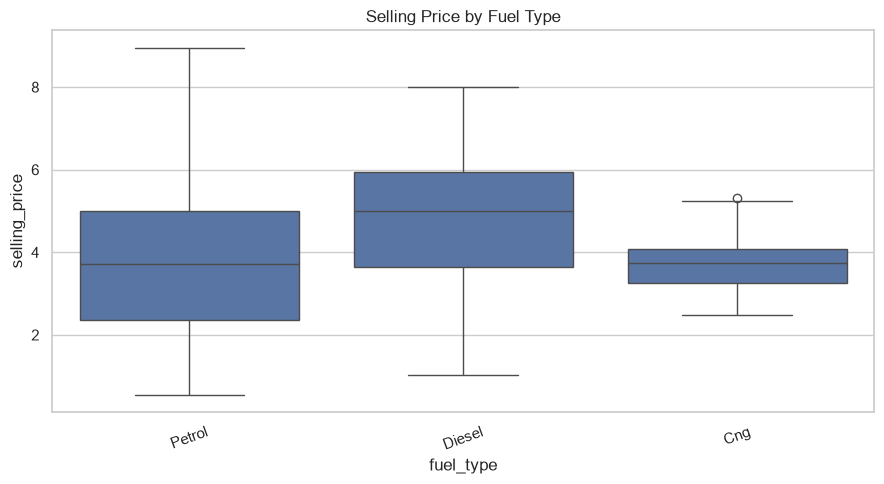

In [22]:
if "fuel_type" in df.columns:
    plt.figure(figsize=(9,5))
    sns.boxplot(data=df,x="fuel_type",y="selling_price")
    plt.title("Selling Price by Fuel Type")
    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR/"price_by_fuel_type.png",dpi=150)
    plt.show()
else:
    print("No fuel_type column; plot skipped.")

## 8. EDA – price vs car age

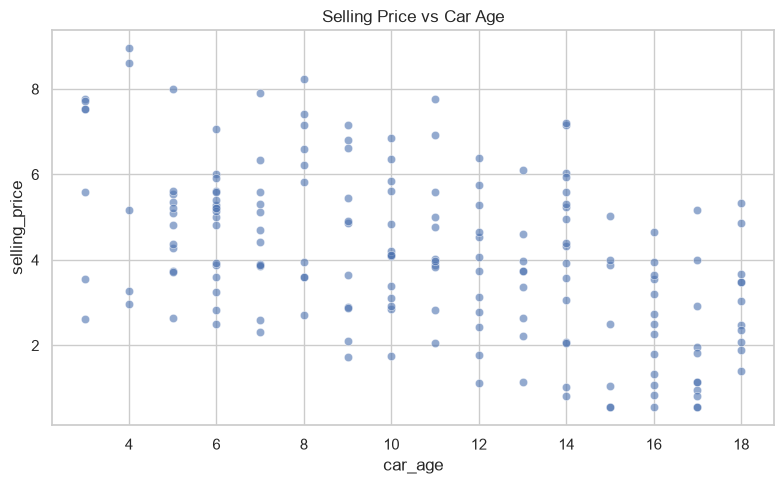

In [23]:
if "car_age" in df.columns:
    plot_df=df.dropna(subset=["car_age"])
    plt.figure(figsize=(8,5))
    sns.scatterplot(data=plot_df,x="car_age",y="selling_price",alpha=.6)
    plt.title("Selling Price vs Car Age")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR/"price_vs_car_age.png",dpi=150)
    plt.show()
else:
    print("No year column; car-age plot skipped.")

## 9. Numeric feature correlation heatmap

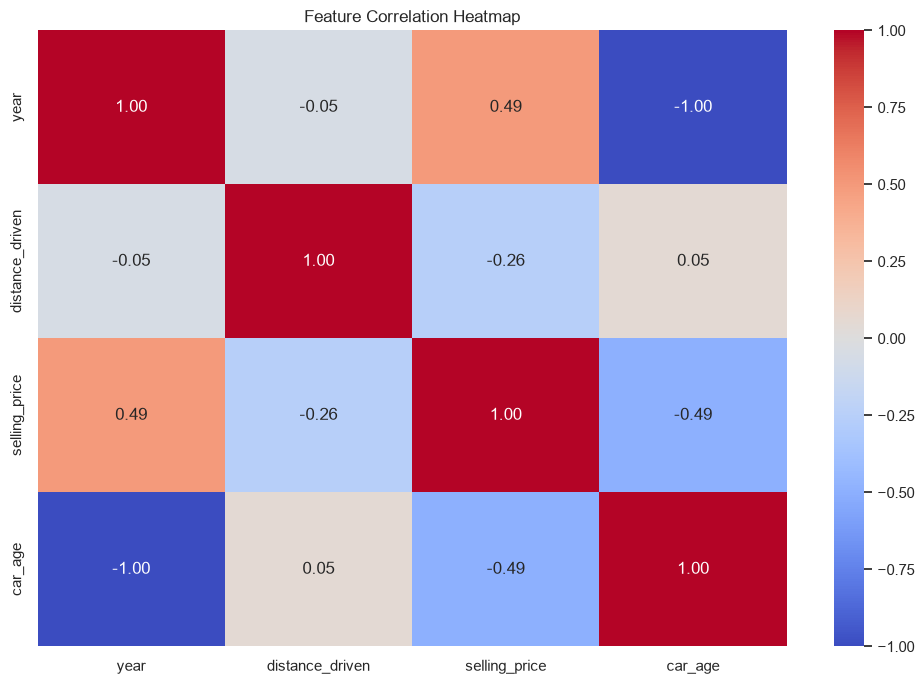

In [24]:
numeric_df=df.select_dtypes(include=np.number)
if numeric_df.shape[1]>=2:
    plt.figure(figsize=(10,7))
    sns.heatmap(numeric_df.corr(),annot=True,cmap="coolwarm",fmt=".2f")
    plt.title("Feature Correlation Heatmap")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR/"correlation_heatmap.png",dpi=150)
    plt.show()
else:
    print("Not enough numeric columns for correlation heatmap.")

## 10. Train/test split

In [25]:
target="selling_price"
X=df.drop(columns=[target]).copy()
y=df[target].copy()
X=X.dropna(axis=1,how="all")
constant_cols=[c for c in X.columns if X[c].nunique(dropna=True)<=1]
X=X.drop(columns=constant_cols)
if len(df)<10:
    raise ValueError(f"Only {len(df)} valid rows remain. Add a larger real dataset; at least 10 rows are required.")
if X.shape[1]==0:
    raise ValueError("No usable predictor columns found.")
numeric_features=X.select_dtypes(include=np.number).columns.tolist()
categorical_features=X.select_dtypes(exclude=np.number).columns.tolist()
print("X:",X.shape,"y:",y.shape)
print("Numeric:",numeric_features)
print("Categorical:",categorical_features)
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=.20,random_state=RANDOM_STATE)
print("Train:",X_train.shape,"Test:",X_test.shape)

X: (180, 7) y: (180,)
Numeric: ['year', 'distance_driven', 'car_age']
Categorical: ['brand', 'model', 'fuel_type', 'transmission_type']
Train: (144, 7) Test: (36, 7)


## 11. Preprocessing and regression models
One-hot encoding handles categorical features; imputers handle missing predictor values.

In [26]:
numeric_pipe=Pipeline([
    ("imputer",SimpleImputer(strategy="median")),
    ("scaler",StandardScaler())
])
categorical_pipe=Pipeline([
    ("imputer",SimpleImputer(strategy="most_frequent")),
    ("onehot",OneHotEncoder(handle_unknown="ignore"))
])
transformers=[]
if numeric_features: transformers.append(("numeric",numeric_pipe,numeric_features))
if categorical_features: transformers.append(("categorical",categorical_pipe,categorical_features))
preprocessor=ColumnTransformer(transformers=transformers,remainder="drop")
estimators={
    "Linear Regression":LinearRegression(),
    "Random Forest":RandomForestRegressor(n_estimators=250,random_state=RANDOM_STATE,min_samples_leaf=2,n_jobs=-1),
    "Gradient Boosting":GradientBoostingRegressor(random_state=RANDOM_STATE)
}
pipelines={name:Pipeline([("preprocessor",preprocessor),("model",est)]) for name,est in estimators.items()}
print("Models:",list(pipelines))

Models: ['Linear Regression', 'Random Forest', 'Gradient Boosting']


## 12. Train and evaluate – MAE, RMSE, R²

In [27]:
results=[]
trained={}
for name,pipe in pipelines.items():
    pipe.fit(X_train,y_train)
    pred=pipe.predict(X_test)
    results.append({
        "Model":name,
        "MAE":mean_absolute_error(y_test,pred),
        "RMSE":np.sqrt(mean_squared_error(y_test,pred)),
        "R2":r2_score(y_test,pred)
    })
    trained[name]=pipe
results_df=pd.DataFrame(results).sort_values("RMSE").reset_index(drop=True)
display(results_df)

,Model,MAE,RMSE,R2
0,Random Forest,0.670855,0.894890,0.735899
1,Gradient Boosting,0.711180,0.922298,0.719474
2,Linear Regression,0.863698,1.062823,0.627478


## 13. Best model and feature importance

Best model by test RMSE: Random Forest


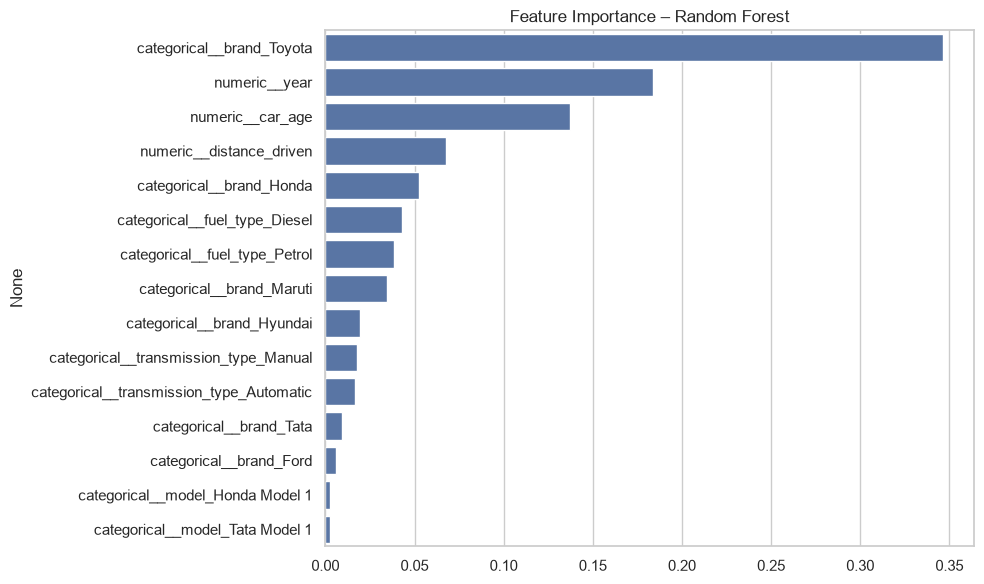

In [28]:
best_model_name=results_df.iloc[0]["Model"]
best_model=trained[best_model_name]
print("Best model by test RMSE:",best_model_name)
tree_name=best_model_name if best_model_name in ["Random Forest","Gradient Boosting"] else "Random Forest"
tree_pipe=trained[tree_name]
tree_est=tree_pipe.named_steps["model"]
feature_names=tree_pipe.named_steps["preprocessor"].get_feature_names_out()
if hasattr(tree_est,"feature_importances_"):
    importance=pd.Series(tree_est.feature_importances_,index=feature_names).sort_values(ascending=False).head(15)
    plt.figure(figsize=(10,6))
    sns.barplot(x=importance.values,y=importance.index)
    plt.title(f"Feature Importance – {tree_name}")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR/"feature_importance.png",dpi=150)
    plt.show()

## 14. Actual vs predicted and sample predictions

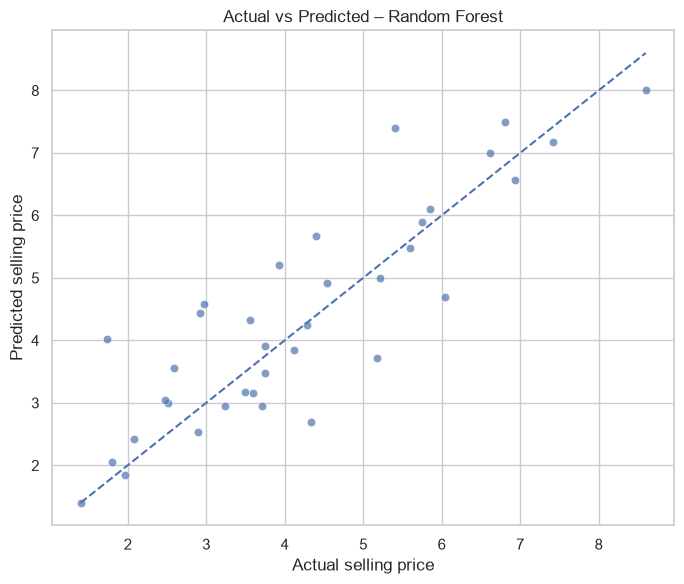

,brand,model,year,fuel_type,transmission_type,distance_driven,car_age,actual_selling_price,predicted_selling_price
19,Maruti,Maruti Model 4,2020.0,Petrol,Manual,116965,6.0,3.24,2.941682
42,Honda,Honda Model 3,2012.0,Diesel,Manual,9946,14.0,6.04,4.693400
153,Ford,Ford Model 2,2016.0,Diesel,Manual,55428,10.0,1.74,4.024961
78,Maruti,Maruti Model 7,2017.0,Petrol,Manual,117801,9.0,2.90,2.526178
145,Hyundai,Hyundai Model 2,2016.0,Diesel,Manual,58944,10.0,2.92,4.437192


In [29]:
pred=best_model.predict(X_test)
plt.figure(figsize=(7,6))
sns.scatterplot(x=y_test,y=pred,alpha=.7)
low=min(float(y_test.min()),float(np.min(pred)))
high=max(float(y_test.max()),float(np.max(pred)))
plt.plot([low,high],[low,high],"--")
plt.xlabel("Actual selling price")
plt.ylabel("Predicted selling price")
plt.title(f"Actual vs Predicted – {best_model_name}")
plt.tight_layout()
plt.savefig(OUTPUT_DIR/"actual_vs_predicted.png",dpi=150)
plt.show()
sample=X_test.head(5).copy()
sample["actual_selling_price"]=y_test.loc[sample.index]
sample["predicted_selling_price"]=best_model.predict(X_test.head(5))
display(sample)

## 15. Save model and metrics

In [30]:
joblib.dump(best_model,OUTPUT_DIR/"best_car_price_model.joblib")
results_df.to_csv(OUTPUT_DIR/"model_metrics.csv",index=False)
print("Saved model and metrics in:",OUTPUT_DIR.resolve())

Saved model and metrics in: F:\gitproject\OIBSIP\OIBSIP_DataScience_Task3_CarPricePrediction_Full\OIBSIP\DataScience-Task3-CarPricePrediction\outputs


## 16. Conclusion – complete after using the real dataset

- Dataset name/source: add the real Kaggle dataset name and source.
- Number of records used: `len(df)`.
- Best model: `best_model_name`.
- Report MAE, RMSE and R² from `results_df`.
- Discuss the most important features shown in the chart.
- Limitations: dataset coverage, location/market differences, missing values and unseen car variants.

**Do not report synthetic sample metrics as real-world results.**